In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = "../data/EduPro Online Platform.xlsx"

users = pd.read_excel(file_path, sheet_name="Users")
teachers = pd.read_excel(file_path, sheet_name="Teachers")
courses = pd.read_excel(file_path, sheet_name="Courses")
transactions = pd.read_excel(file_path, sheet_name="Transactions")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("Users:", users.shape)
print("Teachers:", teachers.shape)
print("Courses:", courses.shape)
print("Transactions:", transactions.shape)

Users: (3000, 5)
Teachers: (60, 7)
Courses: (60, 8)
Transactions: (10000, 7)


In [4]:
print("Users columns:")
print(users.columns.tolist())

print("\nTeachers columns:")
print(teachers.columns.tolist())

print("\nCourses columns:")
print(courses.columns.tolist())

print("\nTransactions columns:")
print(transactions.columns.tolist())

Users columns:
['UserID', 'UserName', 'Age', 'Gender', 'Email']

Teachers columns:
['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise', 'YearsOfExperience', 'TeacherRating']

Courses columns:
['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

Transactions columns:
['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']


In [5]:
print("Missing values in Users:")
print(users.isnull().sum())

print("\nMissing values in Teachers:")
print(teachers.isnull().sum())

print("\nMissing values in Courses:")
print(courses.isnull().sum())

print("\nMissing values in Transactions:")
print(transactions.isnull().sum())

Missing values in Users:
UserID      0
UserName    0
Age         0
Gender      0
Email       0
dtype: int64

Missing values in Teachers:
TeacherID            0
TeacherName          0
Age                  0
Gender               0
Expertise            0
YearsOfExperience    0
TeacherRating        0
dtype: int64

Missing values in Courses:
CourseID          0
CourseName        0
CourseCategory    0
CourseType        0
CourseLevel       0
CoursePrice       0
CourseDuration    0
CourseRating      0
dtype: int64

Missing values in Transactions:
TransactionID      0
UserID             0
CourseID           0
TransactionDate    0
Amount             0
PaymentMethod      0
TeacherID          0
dtype: int64


In [6]:
print("Duplicate rows in Users:", users.duplicated().sum())
print("Duplicate rows in Teachers:", teachers.duplicated().sum())
print("Duplicate rows in Courses:", courses.duplicated().sum())
print("Duplicate rows in Transactions:", transactions.duplicated().sum())

Duplicate rows in Users: 0
Duplicate rows in Teachers: 0
Duplicate rows in Courses: 0
Duplicate rows in Transactions: 0


In [7]:
print("USERS")
print(users.dtypes)

print("\nTEACHERS")
print(teachers.dtypes)

print("\nCOURSES")
print(courses.dtypes)

print("\nTRANSACTIONS")
print(transactions.dtypes)

USERS
UserID      object
UserName    object
Age          int64
Gender      object
Email       object
dtype: object

TEACHERS
TeacherID             object
TeacherName           object
Age                    int64
Gender                object
Expertise             object
YearsOfExperience      int64
TeacherRating        float64
dtype: object

COURSES
CourseID           object
CourseName         object
CourseCategory     object
CourseType         object
CourseLevel        object
CoursePrice       float64
CourseDuration    float64
CourseRating      float64
dtype: object

TRANSACTIONS
TransactionID              object
UserID                     object
CourseID                   object
TransactionDate    datetime64[ns]
Amount                    float64
PaymentMethod              object
TeacherID                  object
dtype: object


In [8]:
print("Invalid UserIDs:",
      (~transactions["UserID"].isin(users["UserID"])).sum())

print("Invalid CourseIDs:",
      (~transactions["CourseID"].isin(courses["CourseID"])).sum())

print("Invalid TeacherIDs:",
      (~transactions["TeacherID"].isin(teachers["TeacherID"])).sum())

Invalid UserIDs: 0
Invalid CourseIDs: 0
Invalid TeacherIDs: 0


In [9]:
master = transactions.merge(
    courses,
    on="CourseID",
    how="left"
)

print("After adding course information:", master.shape)

After adding course information: (10000, 14)


In [10]:
master = master.merge(
    teachers,
    on="TeacherID",
    how="left",
    suffixes=("", "_Teacher")
)

print("After adding teacher information:", master.shape)

After adding teacher information: (10000, 20)


In [11]:
master = master.merge(
    users,
    on="UserID",
    how="left",
    suffixes=("", "_User")
)

print("After adding user information:", master.shape)

After adding user information: (10000, 24)


In [12]:
master.head()

,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating,UserName,Age_User,Gender_User,Email
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040,Digital Marketing,Marketing,Free,Intermediate,0.0,42.68,4.72,Kimberly Miller,49,Male,Cybersecurity,24,4.58,morrisonamanda,33,Female,ganderson@yahoo.com
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040,Scrum Essentials,Project Management,Free,Intermediate,0.0,33.93,3.45,Kimberly Miller,49,Male,Cybersecurity,24,4.58,morrisonamanda,33,Female,ganderson@yahoo.com
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040,Content Marketing,Marketing,Free,Advanced,0.0,18.00,2.98,Kimberly Miller,49,Male,Cybersecurity,24,4.58,morrisonamanda,33,Female,ganderson@yahoo.com
3,TT00004,U00004,CR00048,2025-06-02,0.0,Bank Transfer,TC00040,AI Ethics,Artificial Intelligence,Free,Beginner,0.0,42.70,3.64,Kimberly Miller,49,Male,Cybersecurity,24,4.58,fthornton,23,Female,christensencatherine@outlook.com
4,TT00005,U00004,CR00060,2025-08-10,0.0,PayPal,TC00042,Content Creation,Digital Marketing,Free,Beginner,0.0,8.95,2.14,Yolanda Levine,49,Female,Machine Learning,21,4.97,fthornton,23,Female,christensencatherine@outlook.com


In [13]:
print("Number of instructors:", teachers["TeacherID"].nunique())

print("\nAverage instructor age:",
      round(teachers["Age"].mean(), 2))

print("Average years of experience:",
      round(teachers["YearsOfExperience"].mean(), 2))

print("Average teacher rating:",
      round(teachers["TeacherRating"].mean(), 2))

Number of instructors: 60

Average instructor age: 38.45
Average years of experience: 6.28
Average teacher rating: 3.12


In [14]:
gender_counts = teachers["Gender"].value_counts()

print(gender_counts)

Male      33
Female    27
Name: Gender, dtype: int64


In [15]:
expertise_counts = teachers["Expertise"].value_counts()

print(expertise_counts)

Digital Marketing          11
Cybersecurity               9
Finance                     6
Artificial Intelligence     6
Machine Learning            5
Data Science                5
Project Management          5
Web Development             5
Design                      4
Business                    2
Marketing                   1
Programming                 1
Name: Expertise, dtype: int64


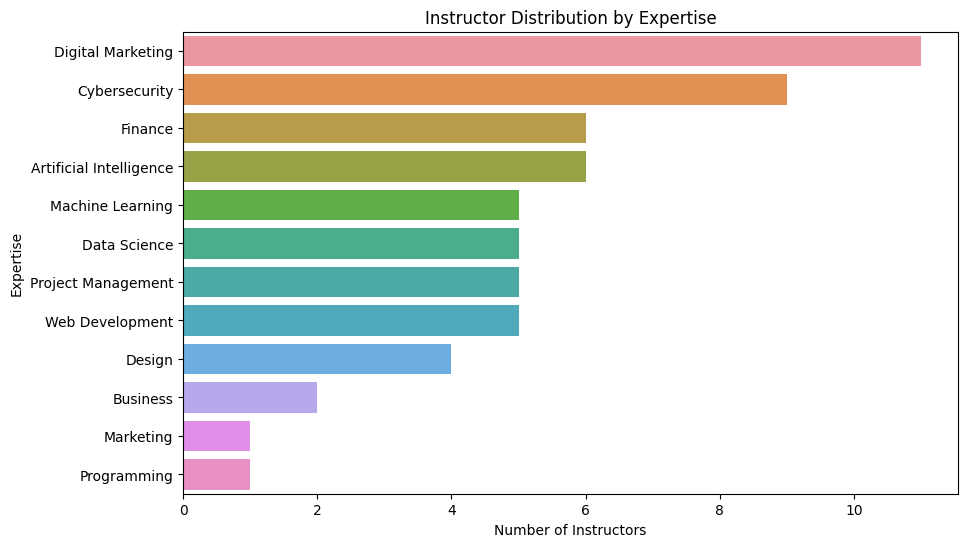

In [16]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=teachers,
    y="Expertise",
    order=teachers["Expertise"].value_counts().index
)

plt.title("Instructor Distribution by Expertise")
plt.xlabel("Number of Instructors")
plt.ylabel("Expertise")

plt.show()

In [17]:
correlation = teachers["YearsOfExperience"].corr(
    teachers["TeacherRating"]
)

print("Correlation between Experience and Teacher Rating:",
      round(correlation, 3))

Correlation between Experience and Teacher Rating: 0.598


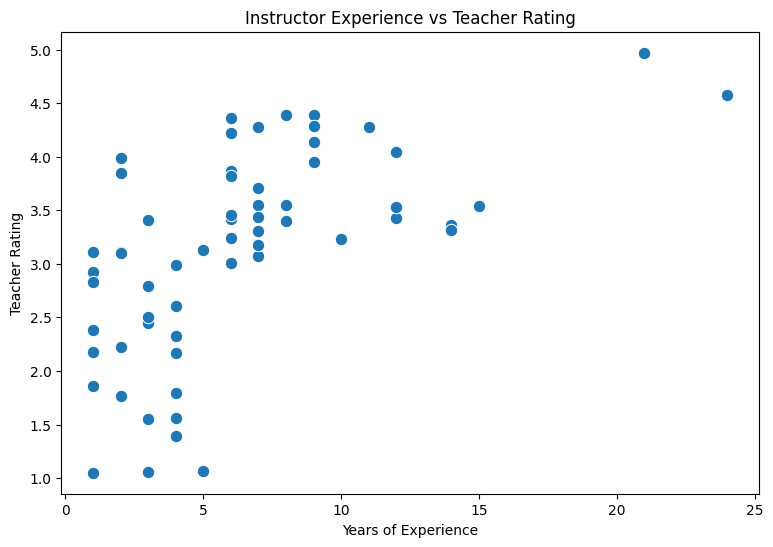

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=teachers,
    x="YearsOfExperience",
    y="TeacherRating",
    s=80
)

plt.title("Instructor Experience vs Teacher Rating")
plt.xlabel("Years of Experience")
plt.ylabel("Teacher Rating")

plt.show()

In [19]:
correlation = teachers["YearsOfExperience"].corr(
    teachers["TeacherRating"]
)

print("Correlation between Experience and Teacher Rating:",
      round(correlation, 3))

Correlation between Experience and Teacher Rating: 0.598


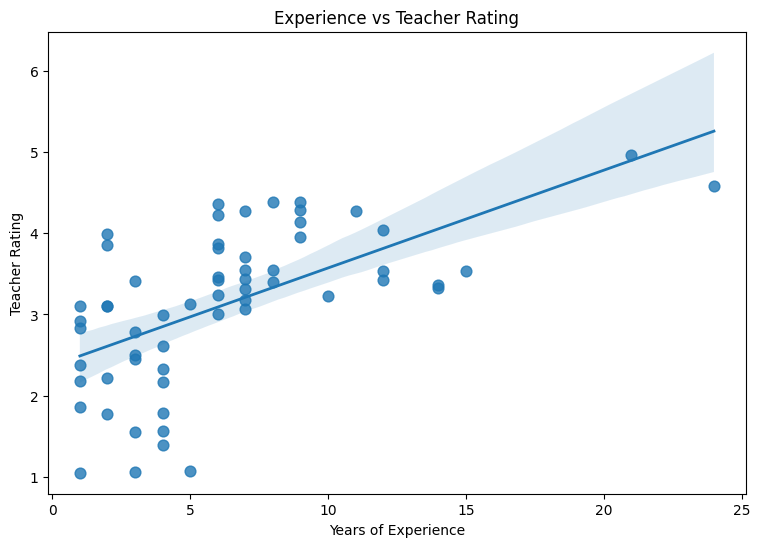

In [20]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=teachers,
    x="YearsOfExperience",
    y="TeacherRating",
    scatter_kws={"s": 60},
    line_kws={"linewidth": 2}
)

plt.title("Experience vs Teacher Rating")
plt.xlabel("Years of Experience")
plt.ylabel("Teacher Rating")

plt.show()

In [1]:
instructor_enrollments = (
    transactions
    .groupby("TeacherID")
    .size()
    .reset_index(name="EnrollmentCount")
)

instructor_enrollments.head()

NameError: name 'transactions' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
file_path = "../data/EduPro Online Platform.xlsx"

users = pd.read_excel(file_path, sheet_name="Users")
teachers = pd.read_excel(file_path, sheet_name="Teachers")
courses = pd.read_excel(file_path, sheet_name="Courses")
transactions = pd.read_excel(file_path, sheet_name="Transactions")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
instructor_enrollments = (
    transactions
    .groupby("TeacherID")
    .size()
    .reset_index(name="EnrollmentCount")
)

instructor_enrollments.head()

,TeacherID,EnrollmentCount
0,TC00001,36
1,TC00002,68
2,TC00003,59
3,TC00004,47
4,TC00005,47


In [5]:
instructor_performance = instructor_enrollments.merge(
    teachers,
    on="TeacherID",
    how="left"
)

instructor_performance.head()

,TeacherID,EnrollmentCount,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,36,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,68,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,59,Amber Torres,32,Male,Design,4,1.56
3,TC00004,47,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,47,David Williams,34,Male,Finance,2,3.11


In [6]:
top_instructors = instructor_performance.sort_values(
    "EnrollmentCount",
    ascending=False
).head(10)

top_instructors[
    [
        "TeacherID",
        "TeacherName",
        "Expertise",
        "YearsOfExperience",
        "TeacherRating",
        "EnrollmentCount"
    ]
]

,TeacherID,TeacherName,Expertise,YearsOfExperience,TeacherRating,EnrollmentCount
41,TC00042,Yolanda Levine,Machine Learning,21,4.97,3061
39,TC00040,Kimberly Miller,Cybersecurity,24,4.58,3025
30,TC00031,Brenda Mercer,Cybersecurity,1,1.86,164
27,TC00028,Timothy Bailey,Business,3,1.06,161
57,TC00058,Andrew Anderson,Web Development,7,3.71,138
32,TC00033,Wesley Garcia,Design,12,4.04,137
7,TC00008,Steven Walker,Data Science,15,3.54,133
26,TC00027,Laurie Michael,Artificial Intelligence,3,1.55,133
55,TC00056,Alexis Everett,Programming,9,3.95,123
52,TC00053,Aaron Kirby,Marketing,9,4.29,120


In [7]:
instructor_enrollments = (
    transactions
    .groupby("TeacherID")
    .size()
    .reset_index(name="EnrollmentCount")
)

instructor_enrollments.head()

,TeacherID,EnrollmentCount
0,TC00001,36
1,TC00002,68
2,TC00003,59
3,TC00004,47
4,TC00005,47


In [8]:
instructor_performance = instructor_enrollments.merge(
    teachers,
    on="TeacherID",
    how="left"
)

instructor_performance.head()

,TeacherID,EnrollmentCount,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,36,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,68,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,59,Amber Torres,32,Male,Design,4,1.56
3,TC00004,47,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,47,David Williams,34,Male,Finance,2,3.11


In [9]:
top_instructors = instructor_performance.sort_values(
    "EnrollmentCount",
    ascending=False
).head(10)

top_instructors[
    [
        "TeacherID",
        "TeacherName",
        "Expertise",
        "YearsOfExperience",
        "TeacherRating",
        "EnrollmentCount"
    ]
]

,TeacherID,TeacherName,Expertise,YearsOfExperience,TeacherRating,EnrollmentCount
41,TC00042,Yolanda Levine,Machine Learning,21,4.97,3061
39,TC00040,Kimberly Miller,Cybersecurity,24,4.58,3025
30,TC00031,Brenda Mercer,Cybersecurity,1,1.86,164
27,TC00028,Timothy Bailey,Business,3,1.06,161
57,TC00058,Andrew Anderson,Web Development,7,3.71,138
32,TC00033,Wesley Garcia,Design,12,4.04,137
7,TC00008,Steven Walker,Data Science,15,3.54,133
26,TC00027,Laurie Michael,Artificial Intelligence,3,1.55,133
55,TC00056,Alexis Everett,Programming,9,3.95,123
52,TC00053,Aaron Kirby,Marketing,9,4.29,120


In [10]:
instructor_performance["RatingTier"] = pd.cut(
    instructor_performance["TeacherRating"],
    bins=[0, 3, 4, 5],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

instructor_performance[
    ["TeacherName", "TeacherRating", "RatingTier"]
].head()

,TeacherName,TeacherRating,RatingTier
0,Leonard Montgomery,3.24,Medium
1,Jill Day,4.14,High
2,Amber Torres,1.56,Low
3,Kristi Scott,4.39,High
4,David Williams,3.11,Medium


In [11]:
rating_tier_counts = (
    instructor_performance["RatingTier"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

print(rating_tier_counts)

Low       21
Medium    28
High      11
Name: RatingTier, dtype: int64


In [12]:
enrollment_by_rating = (
    instructor_performance
    .groupby("RatingTier", observed=True)["EnrollmentCount"]
    .sum()
    .reindex(["Low", "Medium", "High"])
)

print(enrollment_by_rating)

RatingTier
Low       1604
Medium    1576
High      6820
Name: EnrollmentCount, dtype: int64


In [13]:
tier_summary = (
    instructor_performance
    .groupby("RatingTier", observed=True)
    .agg(
        InstructorCount=("TeacherID", "count"),
        TotalEnrollments=("EnrollmentCount", "sum"),
        AverageEnrollments=("EnrollmentCount", "mean"),
        AverageRating=("TeacherRating", "mean")
    )
    .reindex(["Low", "Medium", "High"])
)

tier_summary

,InstructorCount,TotalEnrollments,AverageEnrollments,AverageRating
RatingTier,,,,
Low,21,1604,76.380952,2.070000
Medium,28,1576,56.285714,3.431786
High,11,6820,620.000000,4.358182


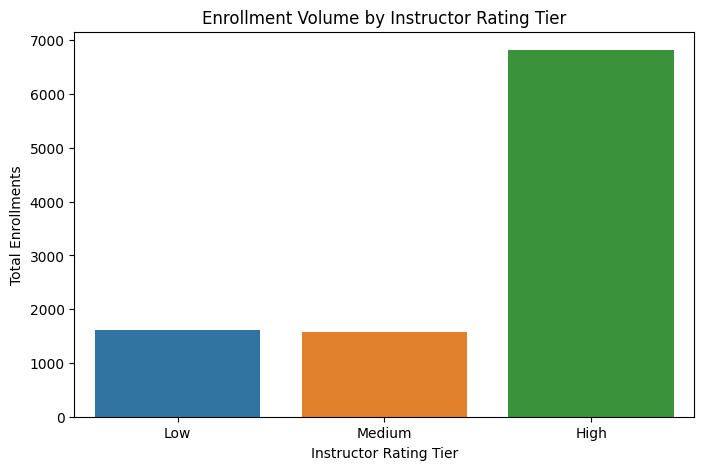

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=tier_summary.reset_index(),
    x="RatingTier",
    y="TotalEnrollments"
)

plt.title("Enrollment Volume by Instructor Rating Tier")
plt.xlabel("Instructor Rating Tier")
plt.ylabel("Total Enrollments")

plt.show()

In [15]:
tier_summary

,InstructorCount,TotalEnrollments,AverageEnrollments,AverageRating
RatingTier,,,,
Low,21,1604,76.380952,2.070000
Medium,28,1576,56.285714,3.431786
High,11,6820,620.000000,4.358182


In [16]:
total_enrollments = instructor_performance["EnrollmentCount"].sum()

high_rating_enrollments = instructor_performance.loc[
    instructor_performance["RatingTier"] == "High",
    "EnrollmentCount"
].sum()

enrollment_influence_ratio = (
    high_rating_enrollments / total_enrollments
) * 100

print("Total Enrollments:", total_enrollments)
print("High-rated Instructor Enrollments:", high_rating_enrollments)
print(
    "Enrollment Influence Ratio:",
    round(enrollment_influence_ratio, 2),
    "%"
)

Total Enrollments: 10000
High-rated Instructor Enrollments: 6820
Enrollment Influence Ratio: 68.2 %


In [17]:
rating_std = teachers["TeacherRating"].std()

rating_consistency_index = (
    1 - (rating_std / 5)
) * 100

print("Teacher Rating Standard Deviation:",
      round(rating_std, 3))

print("Rating Consistency Index:",
      round(rating_consistency_index, 2))

Teacher Rating Standard Deviation: 0.95
Rating Consistency Index: 81.0


In [18]:
average_course_rating = courses["CourseRating"].mean()

print(
    "Average Course Rating:",
    round(average_course_rating, 2)
)

Average Course Rating: 3.1


In [19]:
category_rating = (
    courses
    .groupby("CourseCategory")["CourseRating"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

category_rating

,count,mean
CourseCategory,,
Marketing,5,3.722
Digital Marketing,5,3.656
Data Science,5,3.316
Design,5,3.162
Project Management,5,3.142
Artificial Intelligence,5,3.036
Programming,5,3.036
Finance,5,3.010
Cybersecurity,5,2.902


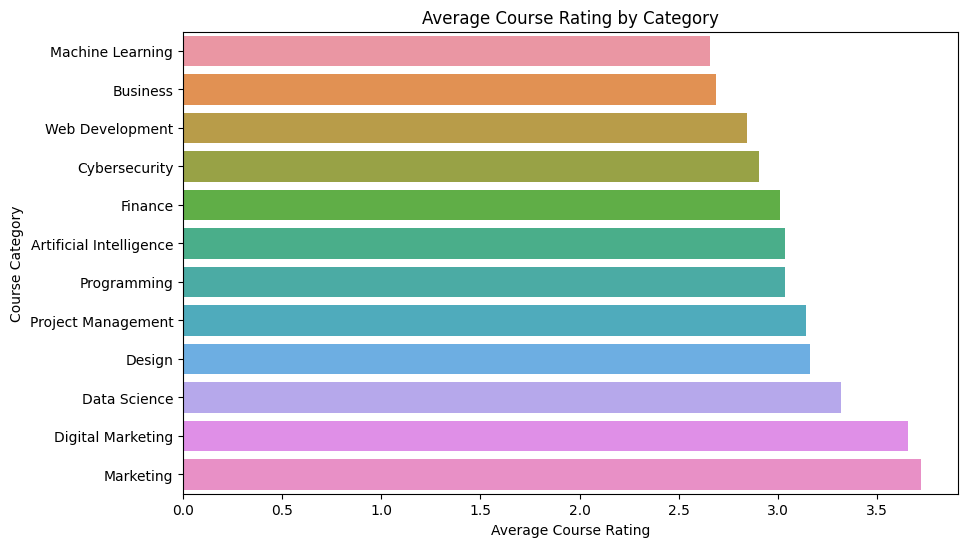

In [20]:
plt.figure(figsize=(10, 6))

category_plot = (
    category_rating
    .sort_values("mean")
    .reset_index()
)

sns.barplot(
    data=category_plot,
    x="mean",
    y="CourseCategory"
)

plt.title("Average Course Rating by Category")
plt.xlabel("Average Course Rating")
plt.ylabel("Course Category")

plt.show()

In [21]:
category_level_rating = pd.pivot_table(
    courses,
    values="CourseRating",
    index="CourseCategory",
    columns="CourseLevel",
    aggfunc="mean"
)

category_level_rating

CourseLevel,Advanced,Beginner,Intermediate
CourseCategory,,,
Artificial Intelligence,NaN,3.1300,2.895000
Business,2.930000,1.9600,2.690000
Cybersecurity,2.380000,4.9400,2.396667
Data Science,2.570000,3.6950,3.310000
Design,2.825000,4.5100,NaN
Digital Marketing,3.520000,3.2900,4.660000
Finance,1.590000,3.3050,3.425000
Machine Learning,2.850000,1.1300,3.230000
Marketing,3.260000,NaN,4.415000


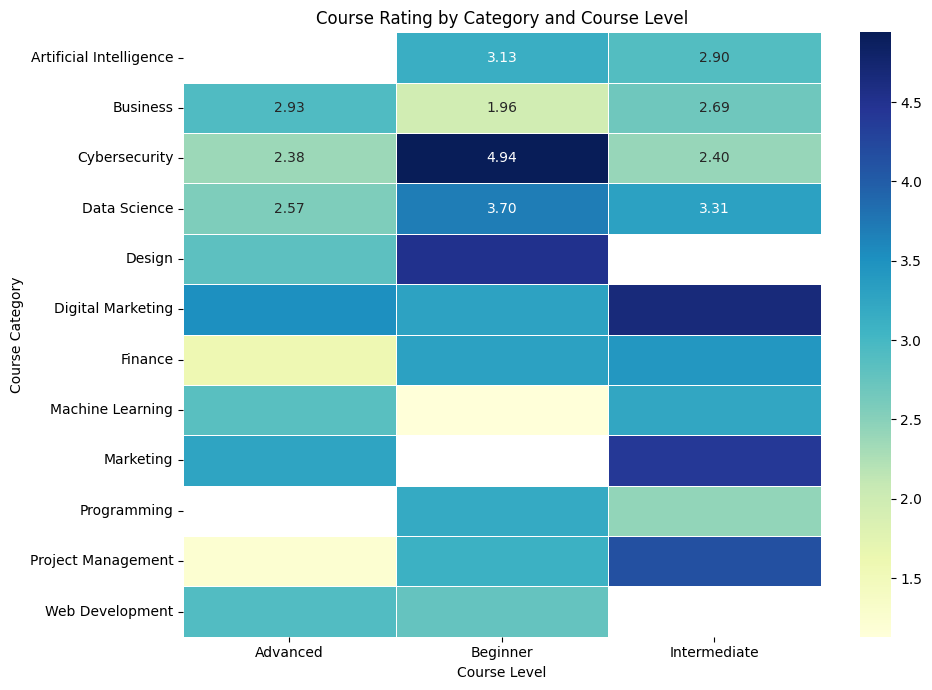

In [22]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    category_level_rating,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Course Rating by Category and Course Level")
plt.xlabel("Course Level")
plt.ylabel("Course Category")

plt.tight_layout()
plt.show()

In [23]:
level_rating = (
    courses
    .groupby("CourseLevel")["CourseRating"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

level_rating

,count,mean
CourseLevel,,
Intermediate,18,3.322778
Beginner,21,3.189048
Advanced,21,2.813810


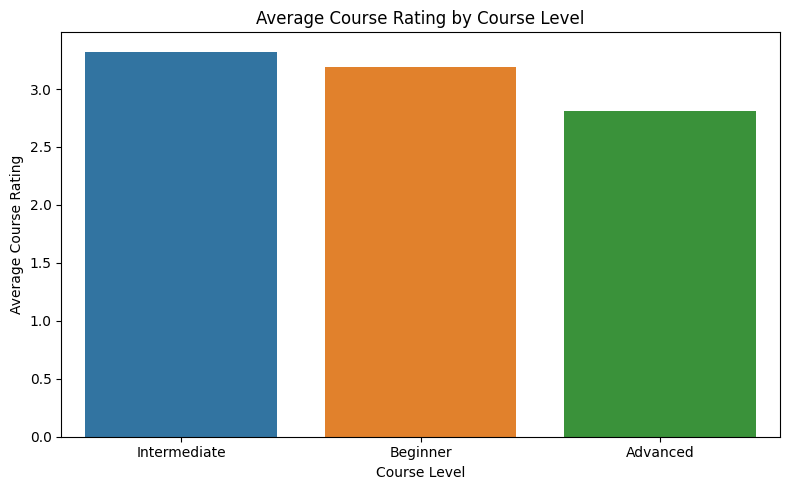

In [24]:
plt.figure(figsize=(8, 5))

level_plot = level_rating.reset_index()

sns.barplot(
    data=level_plot,
    x="CourseLevel",
    y="mean"
)

plt.title("Average Course Rating by Course Level")
plt.xlabel("Course Level")
plt.ylabel("Average Course Rating")

plt.tight_layout()
plt.show()

In [25]:
course_teacher = (
    transactions[["CourseID", "TeacherID"]]
    .drop_duplicates()
    .merge(
        courses[["CourseID", "CourseLevel", "CourseRating"]],
        on="CourseID",
        how="left"
    )
    .merge(
        teachers[["TeacherID", "Gender"]],
        on="TeacherID",
        how="left"
    )
)

gender_level_rating = (
    course_teacher
    .groupby(["Gender", "CourseLevel"])["CourseRating"]
    .mean()
    .unstack()
)

gender_level_rating

CourseLevel,Advanced,Beginner,Intermediate
Gender,,,
Female,2.910392,2.966148,3.327083
Male,2.973433,3.151749,3.495682


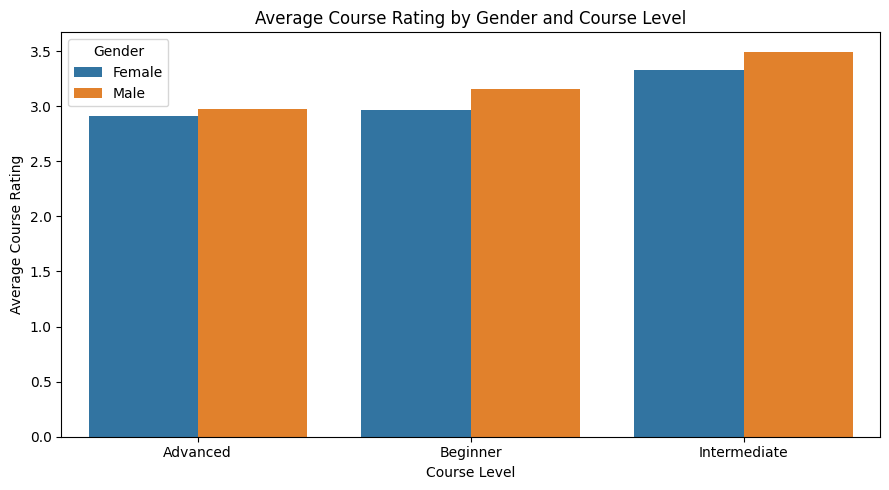

In [26]:
gender_level_plot = gender_level_rating.reset_index().melt(
    id_vars="Gender",
    var_name="CourseLevel",
    value_name="AverageRating"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=gender_level_plot,
    x="CourseLevel",
    y="AverageRating",
    hue="Gender"
)

plt.title("Average Course Rating by Gender and Course Level")
plt.xlabel("Course Level")
plt.ylabel("Average Course Rating")

plt.tight_layout()
plt.show()

In [27]:
expertise_performance = (
    teachers
    .groupby("Expertise")["TeacherRating"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

expertise_performance

,count,mean
Expertise,,
Marketing,1,4.290000
Machine Learning,5,4.234000
Programming,1,3.950000
Cybersecurity,9,3.468889
Finance,6,3.265000
Artificial Intelligence,6,3.173333
Digital Marketing,11,3.050000
Data Science,5,3.030000
Project Management,5,2.664000


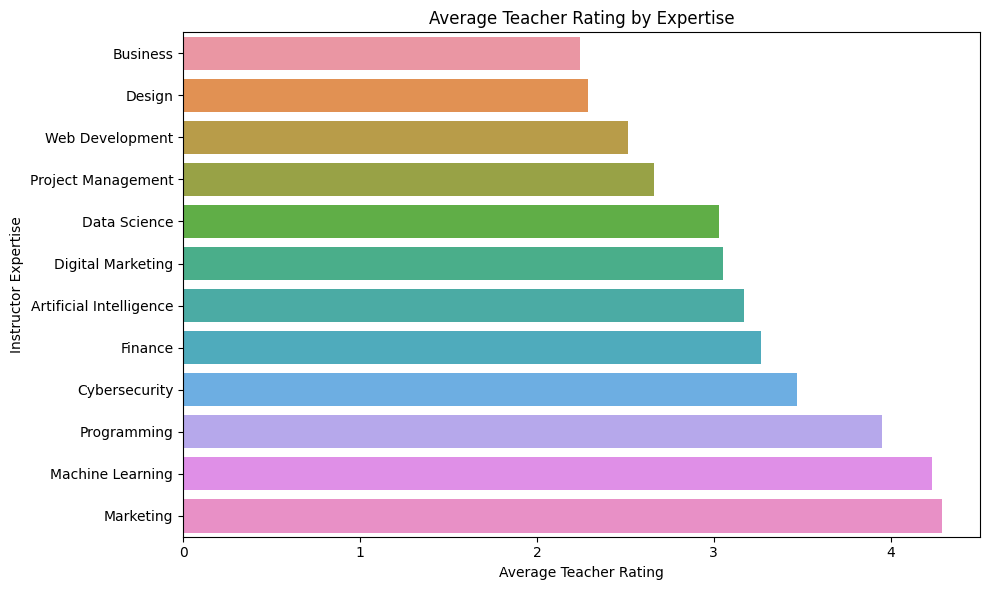

In [28]:
plt.figure(figsize=(10, 6))

expertise_plot = expertise_performance.sort_values("mean").reset_index()

sns.barplot(
    data=expertise_plot,
    x="mean",
    y="Expertise"
)

plt.title("Average Teacher Rating by Expertise")
plt.xlabel("Average Teacher Rating")
plt.ylabel("Instructor Expertise")

plt.tight_layout()
plt.show()